In [1]:
import pandas as pd
import numpy as np

# load STATA file
df = pd.read_stata("/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_Round_14_SP_File.dta")

# save as csv file
df.to_csv("/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_Round_14_SP_File.csv", index=False)

In [2]:
# read dementia status csv file
df_dementia = pd.read_csv("/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_cognition_r14.csv")

# read sp14 csv file
df_sp14 = pd.read_csv("/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_Round_14_SP_File.csv")

# merge the two dataframes on the common identifier 'spid' from df_dementia to df_sp14 adding 'demclas' column
df_merged = pd.merge(df_sp14, df_dementia[['spid', 'demclas']], on='spid', how='left')
# save the merged dataframe as a new csv file
df_merged.to_csv("/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_Round_14_SP_File_with_dementia_status.csv", index=False)

/var/folders/pd/4sdc1cc90lb9pt68g676htzw0000gn/T/ipykernel_10819/3238408625.py:5: DtypeWarning: Columns (21) have mixed types. Specify dtype option on import or set low_memory=False.
  df_sp14 = pd.read_csv("/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_Round_14_SP_File.csv")


In [1]:
import os
import pandas as pd
import pyreadr

# Folder containing the NHATS_cognition_r*.RDa files
data_dir = "/Users/pageguo/Desktop/nhats_data_retrieval/nhats RDA files"

all_rounds = []

for r in range(1, 15):
    file_path = os.path.join(data_dir, f"NHATS_cognition_r{r}.RDa")

    # Read RDa file
    result = pyreadr.read_r(file_path)

    # Most RDa files contain one R object.
    # This extracts the first object as a pandas DataFrame.
    df = next(iter(result.values()))

    # Add round number
    df["rnd"] = r

    # Keep only columns needed.
    # Adjust "spid" below if your participant ID column has a different name.
    keep_cols = ["spid", "rnd", "demclas"]

    df = df[keep_cols]

    all_rounds.append(df)

# Combine all rounds into one large dataset
combined = pd.concat(all_rounds, ignore_index=True)

# Output to CSV
combined.to_csv("/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_cognition_combined_r1_r14.csv", index=False)

print("Saved file: NHATS_cognition_combined_r1_r14.csv")
print(combined.head())
print(combined.shape)

Saved file: NHATS_cognition_combined_r1_r14.csv
         spid  rnd  demclas
0  10000003.0    1      3.0
1  10000004.0    1      3.0
2  10000005.0    1      3.0
3  10000006.0    1      3.0
4  10000007.0    1      3.0
(88499, 3)


In [2]:
import pandas as pd

# Read data
df = pd.read_csv("/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_cognition_combined_r1_r14.csv")

# 1. Overall descriptive statistics
n_unique_spid = df["spid"].nunique()

participants_by_round = (
    df.groupby("rnd")["spid"]
    .nunique()
    .reset_index(name="n_participants")
)

demclas_distribution = (
    df["demclas"]
    .value_counts(dropna=False)
    .sort_index()
    .reset_index()
)

demclas_distribution.columns = ["demclas", "count"]
demclas_distribution["percent"] = (
    demclas_distribution["count"] / len(df) * 100
)

# 2. Participants present in all 14 rounds
rounds_per_spid = df.groupby("spid")["rnd"].nunique()

spid_all_14 = rounds_per_spid[rounds_per_spid == 14].index
n_spid_all_14 = len(spid_all_14)

# 3. Among those present in all 14 rounds, identify demclas changes
df_all_14 = df[df["spid"].isin(spid_all_14)].copy()

demclas_nunique = (
    df_all_14.groupby("spid")["demclas"]
    .nunique()
)

spid_with_demclas_change = demclas_nunique[demclas_nunique > 1].index
n_demclas_change = len(spid_with_demclas_change)

n_no_demclas_change = n_spid_all_14 - n_demclas_change

# Print results
print("Total unique spid:", n_unique_spid)
print("\nParticipants by round:")
print(participants_by_round)

print("\nOverall demclas distribution:")
print(demclas_distribution)

print("\nParticipants present in all 14 rounds:", n_spid_all_14)

print("\nAmong participants present in all 14 rounds:")
print("Had any demclas change:", n_demclas_change)
print("No demclas change:", n_no_demclas_change)
print(
    "Percent with demclas change:",
    round(n_demclas_change / n_spid_all_14 * 100, 1),
    "%"
)

Total unique spid: 18439

Participants by round:
    rnd  n_participants
0     1            8245
1     2            7075
2     3            5799
3     4            4737
4     5            8334
5     6            7276
6     7            6312
7     8            5547
8     9            4389
9    10            4389
10   11            3817
11   12            6327
12   13            8597
13   14            7655

Overall demclas distribution:
   demclas  count    percent
0     -9.0   1824   2.061040
1     -1.0   7443   8.410265
2      1.0  10721  12.114261
3      2.0   7827   8.844168
4      3.0  60684  68.570266

Participants present in all 14 rounds: 1322

Among participants present in all 14 rounds:
Had any demclas change: 669
No demclas change: 653
Percent with demclas change: 50.6 %


Basic dataset information


,Statistic,Value
0,Dataset rows,88499
1,Dataset columns,4
2,Unique participants,18439
3,Number of rounds,14
4,Minimum round,1
5,Maximum round,14
6,Missing rnd values,0
7,Missing demclas values,0


Rounds:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
Preview of dataset:


,spid,rnd,demclas,demclas_label
0,10000003.0,1,3.0,No dementia
1,10000003.0,2,3.0,No dementia
2,10000003.0,3,2.0,Possible dementia
3,10000003.0,4,3.0,No dementia
4,10000003.0,5,3.0,No dementia


Participants by round


,rnd,n_participants
0,1,8245
1,2,7075
2,3,5799
3,4,4737
4,5,8334
5,6,7276
6,7,6312
7,8,5547
8,9,4389
9,10,4389


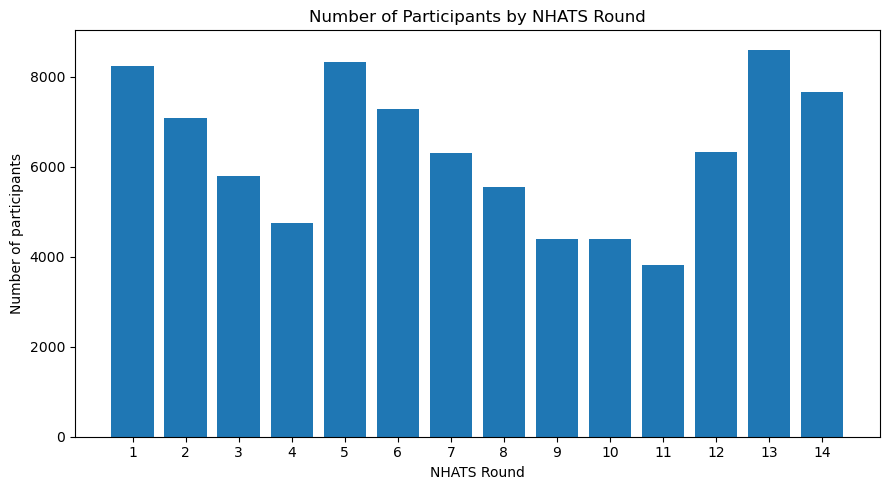

Overall dementia classification distribution


,demclas_label,count,percent
0,No dementia,60684,68.570266
1,Probable dementia,10721,12.114261
2,Possible dementia,7827,8.844168
3,Inapplicable,7443,8.410265
4,Missing / not ascertained,1824,2.061040


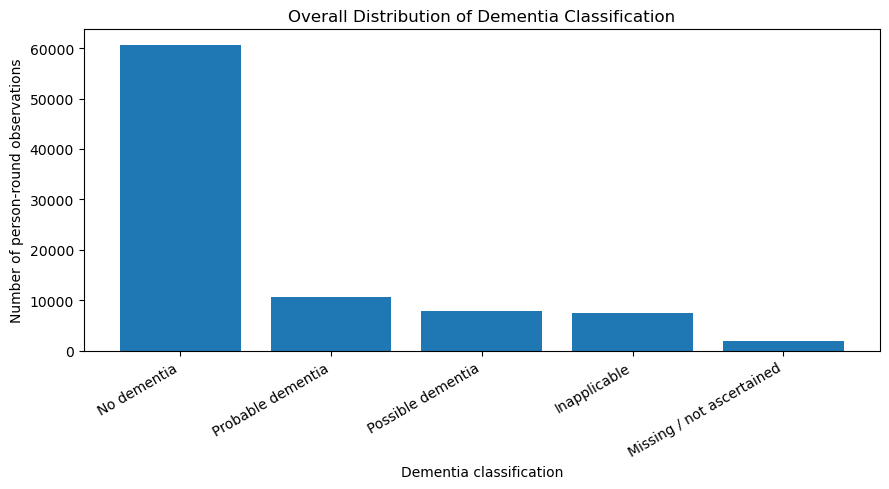

Dementia classification counts by round


,rnd,demclas_label,count
0,1,Inapplicable,468
1,1,Missing / not ascertained,168
2,1,No dementia,5575
3,1,Possible dementia,996
4,1,Probable dementia,1038
...,...,...,...
65,14,Inapplicable,618
66,14,Missing / not ascertained,98
67,14,No dementia,5388
68,14,Possible dementia,679


Dementia classification count table by round


demclas_label,Inapplicable,Missing / not ascertained,No dementia,Possible dementia,Probable dementia
rnd,,,,,
1,468,168,5575,996,1038
2,829,190,4540,672,844
3,736,179,3688,478,718
4,544,156,3016,405,616
5,579,188,5823,779,965
6,689,177,4975,572,863
7,588,158,4269,526,771
8,489,112,3823,438,685
9,351,77,3025,326,610


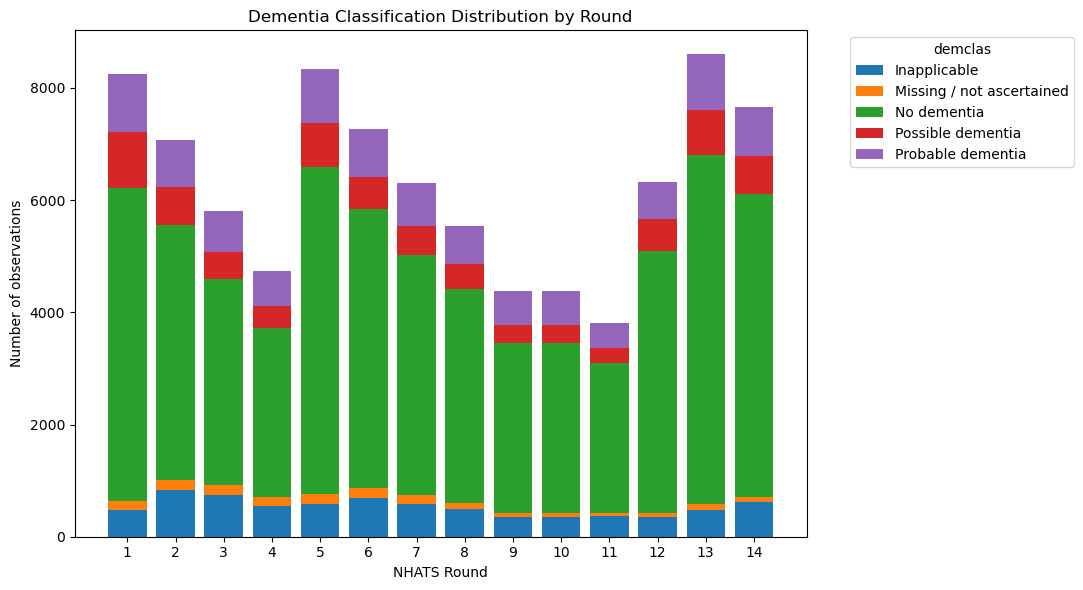

Dementia classification percentage table by round


demclas_label,Inapplicable,Missing / not ascertained,No dementia,Possible dementia,Probable dementia
rnd,,,,,
1,5.676167,2.037599,67.616737,12.080049,12.589448
2,11.717314,2.685512,64.169611,9.498233,11.929329
3,12.691843,3.086739,63.597172,8.242800,12.381445
4,11.484062,3.293224,63.668989,8.549715,13.004011
5,6.947444,2.255820,69.870410,9.347252,11.579074
6,9.469489,2.432655,68.375481,7.861462,11.860913
7,9.315589,2.503169,67.633080,8.333333,12.214829
8,8.815576,2.019109,68.920137,7.896160,12.349017
9,7.997266,1.754386,68.922306,7.427660,13.898382


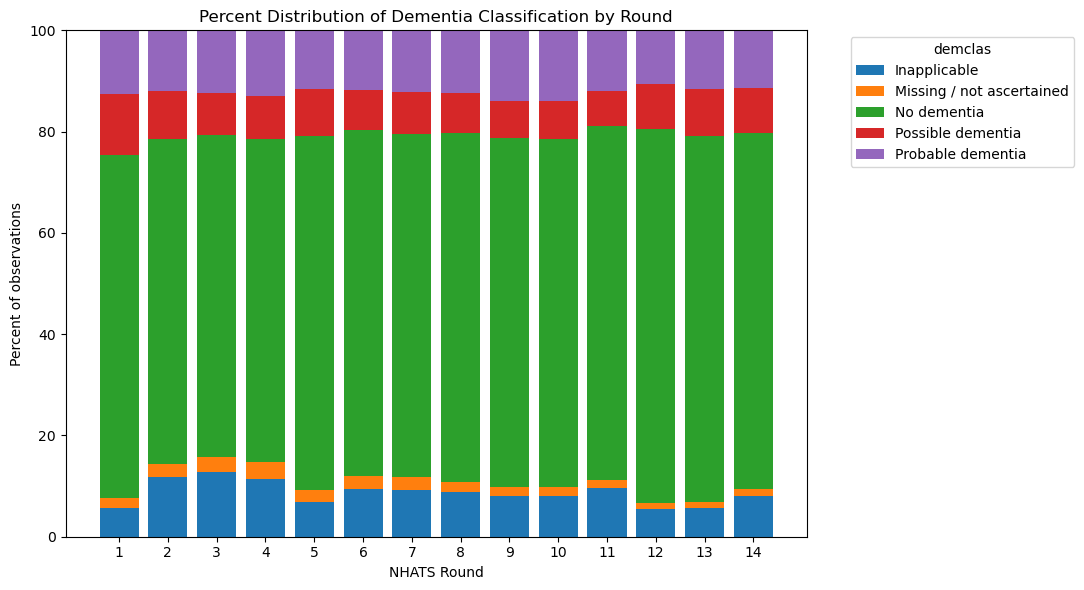

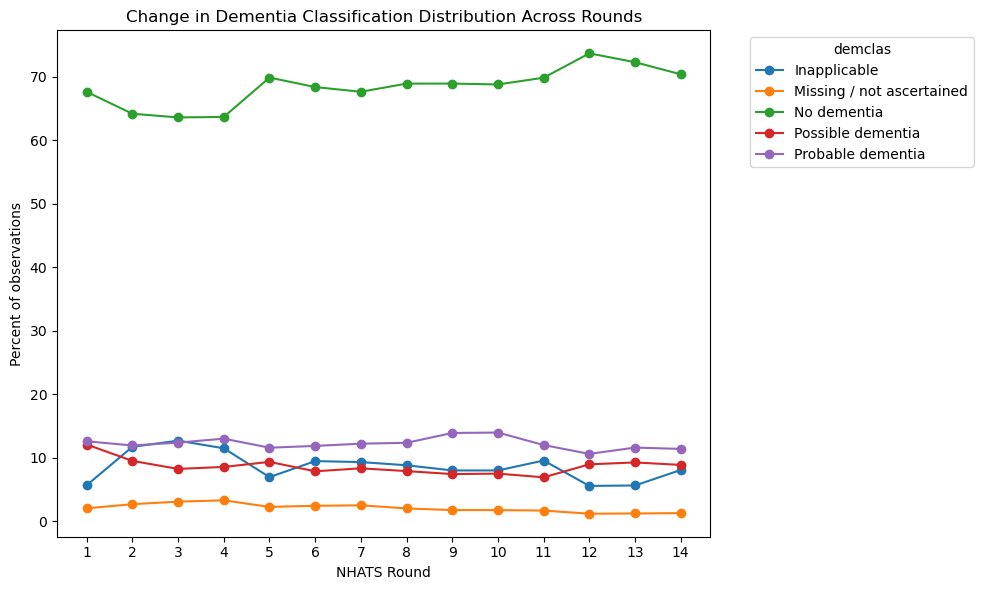

Number of rounds observed per participant


,n_rounds_observed,n_participants
0,1,2471
1,2,4619
2,3,3910
3,4,1149
4,5,477
5,6,713
6,7,657
7,8,742
8,9,116
9,10,1639


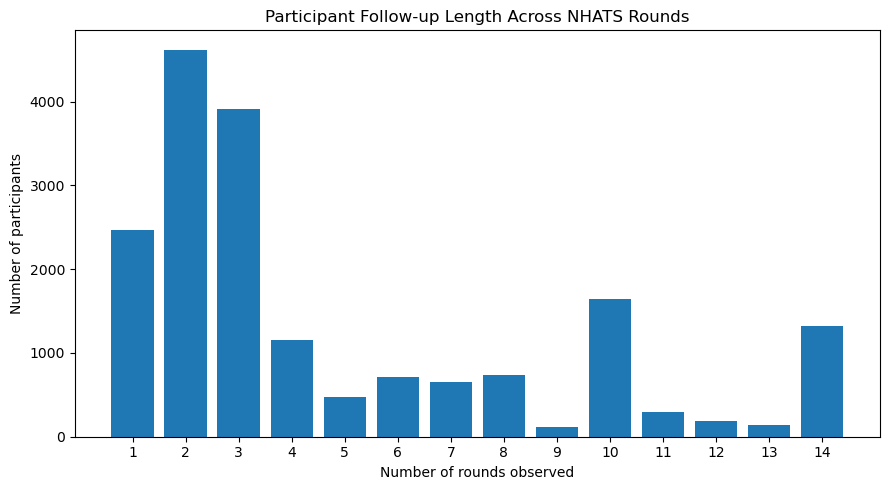

Participants present in all 14 rounds


,Statistic,Value
0,Participants present in all 14 rounds,1322
1,Rows for participants present in all 14 rounds,18508
2,Expected rows if each has 14 rounds,18508


Dementia classification change among participants present in all 14 rounds


,change_status,n_participants,percent
0,Any demclas change,669,50.605144
1,No demclas change,653,49.394856


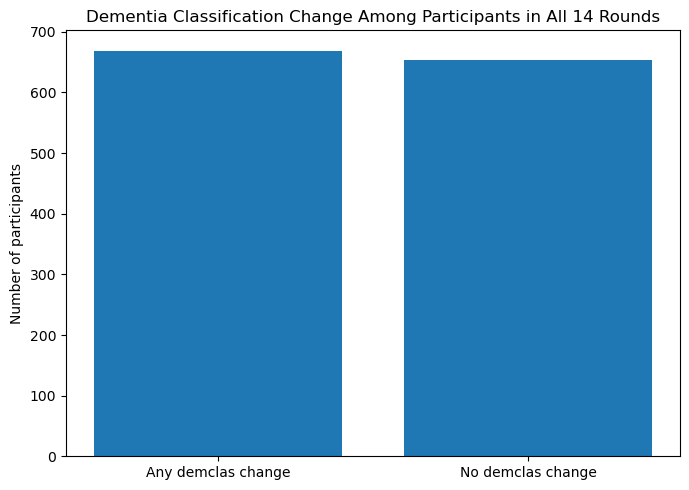

Top 20 consecutive-round dementia classification transitions


,transition,count,percent
0,No dementia → No dementia,44496,63.511276
1,Probable dementia → Probable dementia,6066,8.658293
2,No dementia → Possible dementia,3301,4.711676
3,Possible dementia → No dementia,2679,3.823865
4,Inapplicable → Inapplicable,2385,3.404225
5,Possible dementia → Possible dementia,1957,2.793320
6,Probable dementia → Inapplicable,1705,2.433628
7,No dementia → Inapplicable,1666,2.377962
8,No dementia → Probable dementia,1338,1.909792
9,Possible dementia → Probable dementia,1146,1.635741


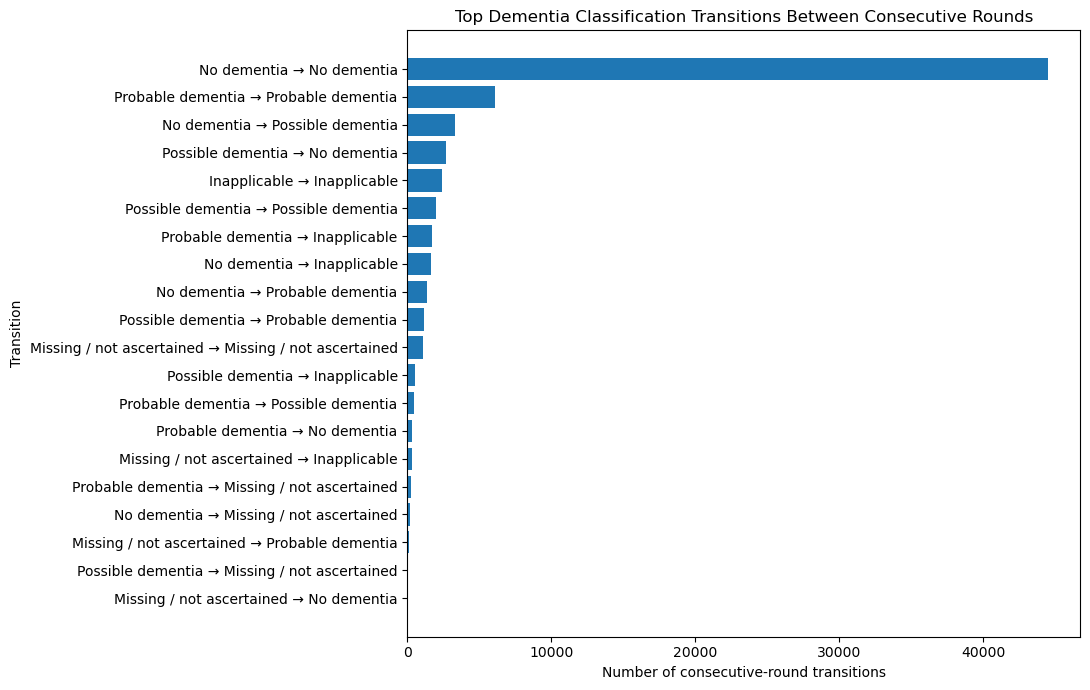

Consecutive-round dementia classification transition matrix


next_demclas_label,Inapplicable,Missing / not ascertained,No dementia,Possible dementia,Probable dementia
demclas_label,,,,,
Inapplicable,2385,0,0,0,0
Missing / not ascertained,313,1087,41,16,88
No dementia,1666,163,44496,3301,1338
Possible dementia,524,57,2679,1957,1146
Probable dementia,1705,229,352,451,6066


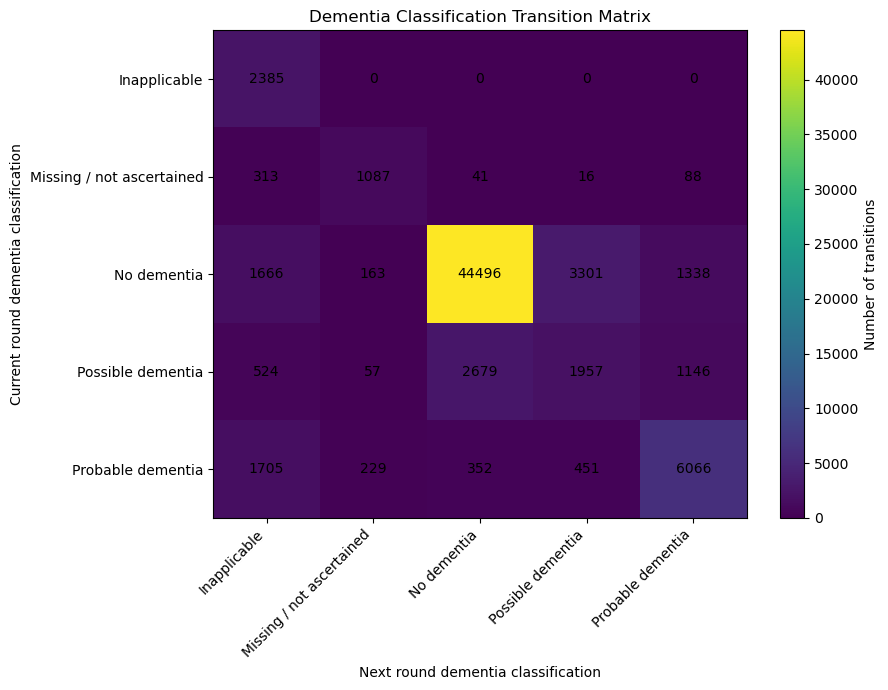

Transition direction counts


,transition_direction,count,percent
0,Stable,52519,74.962889
1,Non-classifiable / missing,8274,11.809877
2,Worsened,5785,8.257208
3,Improved,3482,4.970026


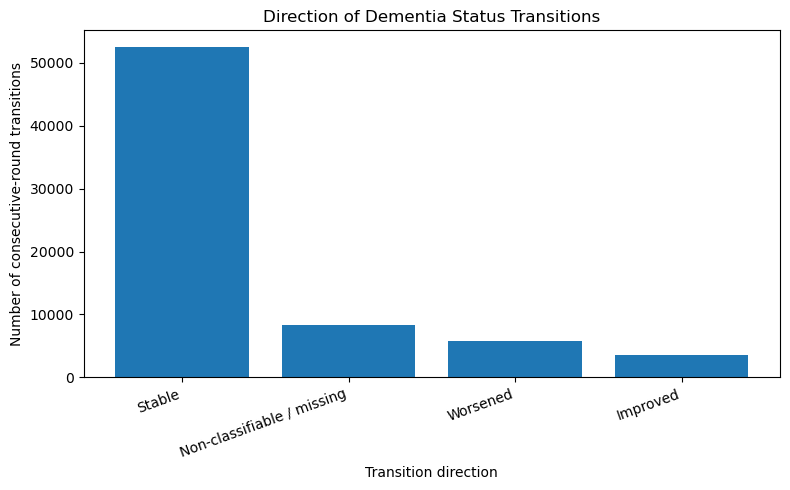

Notebook visualization complete.


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ============================================================
# 1. Load dataset
# ============================================================

csv_path = "/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_cognition_combined_r1_r14.csv"

df = pd.read_csv(csv_path)

# Basic checks
required_cols = ["spid", "rnd", "demclas"]
missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# Make sure round and dementia class are numeric
df["rnd"] = pd.to_numeric(df["rnd"], errors="coerce")
df["demclas"] = pd.to_numeric(df["demclas"], errors="coerce")

# Label dementia classes
# Edit these labels if your NHATS coding guide defines them differently.
demclas_labels = {
    -9: "Missing / not ascertained",
    -1: "Inapplicable",
    1: "Probable dementia",
    2: "Possible dementia",
    3: "No dementia"
}

df["demclas_label"] = df["demclas"].map(demclas_labels)
df["demclas_label"] = df["demclas_label"].fillna(df["demclas"].astype(str))

# Sort dataset
df = df.sort_values(["spid", "rnd"]).reset_index(drop=True)

# ============================================================
# 2. Basic dataset summary
# ============================================================

basic_info = pd.DataFrame({
    "Statistic": [
        "Dataset rows",
        "Dataset columns",
        "Unique participants",
        "Number of rounds",
        "Minimum round",
        "Maximum round",
        "Missing rnd values",
        "Missing demclas values"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df["spid"].nunique(),
        df["rnd"].nunique(),
        df["rnd"].min(),
        df["rnd"].max(),
        df["rnd"].isna().sum(),
        df["demclas"].isna().sum()
    ]
})

print("Basic dataset information")
display(basic_info)

print("Rounds:")
print(sorted(df["rnd"].dropna().unique()))

print("Preview of dataset:")
display(df.head())


# ============================================================
# 3. Participants per round
# ============================================================

participants_by_round = (
    df.groupby("rnd")["spid"]
    .nunique()
    .reset_index(name="n_participants")
)

print("Participants by round")
display(participants_by_round)

plt.figure(figsize=(9, 5))
plt.bar(
    participants_by_round["rnd"],
    participants_by_round["n_participants"]
)
plt.xlabel("NHATS Round")
plt.ylabel("Number of participants")
plt.title("Number of Participants by NHATS Round")
plt.xticks(participants_by_round["rnd"])
plt.tight_layout()
plt.show()


# ============================================================
# 4. Overall dementia classification distribution
# ============================================================

demclas_counts = (
    df["demclas_label"]
    .value_counts()
    .reset_index()
)

demclas_counts.columns = ["demclas_label", "count"]
demclas_counts["percent"] = demclas_counts["count"] / len(df) * 100

print("Overall dementia classification distribution")
display(demclas_counts)

plt.figure(figsize=(9, 5))
plt.bar(
    demclas_counts["demclas_label"],
    demclas_counts["count"]
)
plt.xlabel("Dementia classification")
plt.ylabel("Number of person-round observations")
plt.title("Overall Distribution of Dementia Classification")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# ============================================================
# 5. Dementia classification distribution by round: counts
# ============================================================

demclas_by_round_counts = (
    df.groupby(["rnd", "demclas_label"])
    .size()
    .reset_index(name="count")
)

print("Dementia classification counts by round")
display(demclas_by_round_counts)

demclas_by_round_pivot = demclas_by_round_counts.pivot(
    index="rnd",
    columns="demclas_label",
    values="count"
).fillna(0)

print("Dementia classification count table by round")
display(demclas_by_round_pivot)

plt.figure(figsize=(11, 6))

bottom = None

for col in demclas_by_round_pivot.columns:
    if bottom is None:
        plt.bar(
            demclas_by_round_pivot.index,
            demclas_by_round_pivot[col],
            label=col
        )
        bottom = demclas_by_round_pivot[col].copy()
    else:
        plt.bar(
            demclas_by_round_pivot.index,
            demclas_by_round_pivot[col],
            bottom=bottom,
            label=col
        )
        bottom += demclas_by_round_pivot[col]

plt.xlabel("NHATS Round")
plt.ylabel("Number of observations")
plt.title("Dementia Classification Distribution by Round")
plt.xticks(demclas_by_round_pivot.index)
plt.legend(title="demclas", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


# ============================================================
# 6. Dementia classification distribution by round: percentages
# ============================================================

demclas_by_round_pct = demclas_by_round_pivot.div(
    demclas_by_round_pivot.sum(axis=1),
    axis=0
) * 100

print("Dementia classification percentage table by round")
display(demclas_by_round_pct)

plt.figure(figsize=(11, 6))

bottom = None

for col in demclas_by_round_pct.columns:
    if bottom is None:
        plt.bar(
            demclas_by_round_pct.index,
            demclas_by_round_pct[col],
            label=col
        )
        bottom = demclas_by_round_pct[col].copy()
    else:
        plt.bar(
            demclas_by_round_pct.index,
            demclas_by_round_pct[col],
            bottom=bottom,
            label=col
        )
        bottom += demclas_by_round_pct[col]

plt.xlabel("NHATS Round")
plt.ylabel("Percent of observations")
plt.title("Percent Distribution of Dementia Classification by Round")
plt.xticks(demclas_by_round_pct.index)
plt.ylim(0, 100)
plt.legend(title="demclas", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


# ============================================================
# 7. Line plot: percentage of each dementia class over rounds
# ============================================================

plt.figure(figsize=(10, 6))

for col in demclas_by_round_pct.columns:
    plt.plot(
        demclas_by_round_pct.index,
        demclas_by_round_pct[col],
        marker="o",
        label=col
    )

plt.xlabel("NHATS Round")
plt.ylabel("Percent of observations")
plt.title("Change in Dementia Classification Distribution Across Rounds")
plt.xticks(demclas_by_round_pct.index)
plt.legend(title="demclas", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


# ============================================================
# 8. Number of rounds observed per participant
# ============================================================

rounds_per_spid = (
    df.groupby("spid")["rnd"]
    .nunique()
    .reset_index(name="n_rounds_observed")
)

rounds_observed_counts = (
    rounds_per_spid["n_rounds_observed"]
    .value_counts()
    .sort_index()
    .reset_index()
)

rounds_observed_counts.columns = ["n_rounds_observed", "n_participants"]

print("Number of rounds observed per participant")
display(rounds_observed_counts)

plt.figure(figsize=(9, 5))
plt.bar(
    rounds_observed_counts["n_rounds_observed"],
    rounds_observed_counts["n_participants"]
)
plt.xlabel("Number of rounds observed")
plt.ylabel("Number of participants")
plt.title("Participant Follow-up Length Across NHATS Rounds")
plt.xticks(rounds_observed_counts["n_rounds_observed"])
plt.tight_layout()
plt.show()


# ============================================================
# 9. Participants present in all 14 rounds
# ============================================================

spid_all_14 = rounds_per_spid.loc[
    rounds_per_spid["n_rounds_observed"] == 14,
    "spid"
]

df_all_14 = df[df["spid"].isin(spid_all_14)].copy()

all14_summary = pd.DataFrame({
    "Statistic": [
        "Participants present in all 14 rounds",
        "Rows for participants present in all 14 rounds",
        "Expected rows if each has 14 rounds"
    ],
    "Value": [
        len(spid_all_14),
        df_all_14.shape[0],
        len(spid_all_14) * 14
    ]
})

print("Participants present in all 14 rounds")
display(all14_summary)


# ============================================================
# 10. Dementia classification change among all-14-round participants
# ============================================================

demclas_nunique_all14 = (
    df_all_14.groupby("spid")["demclas"]
    .nunique()
    .reset_index(name="n_unique_demclas")
)

demclas_nunique_all14["change_status"] = demclas_nunique_all14[
    "n_unique_demclas"
].apply(lambda x: "Any demclas change" if x > 1 else "No demclas change")

change_counts = (
    demclas_nunique_all14["change_status"]
    .value_counts()
    .reset_index()
)

change_counts.columns = ["change_status", "n_participants"]
change_counts["percent"] = (
    change_counts["n_participants"]
    / change_counts["n_participants"].sum()
    * 100
)

print("Dementia classification change among participants present in all 14 rounds")
display(change_counts)

plt.figure(figsize=(7, 5))
plt.bar(
    change_counts["change_status"],
    change_counts["n_participants"]
)
plt.xlabel("")
plt.ylabel("Number of participants")
plt.title("Dementia Classification Change Among Participants in All 14 Rounds")
plt.tight_layout()
plt.show()


# ============================================================
# 11. Consecutive-round transition counts
# ============================================================

df_transition = df[["spid", "rnd", "demclas_label"]].copy()

df_transition = df_transition.sort_values(["spid", "rnd"])

df_transition["next_rnd"] = df_transition.groupby("spid")["rnd"].shift(-1)
df_transition["next_demclas_label"] = df_transition.groupby("spid")[
    "demclas_label"
].shift(-1)

# Keep only consecutive round transitions, e.g., round 1 -> 2
df_transition = df_transition[
    df_transition["next_rnd"] == df_transition["rnd"] + 1
].copy()

df_transition["transition"] = (
    df_transition["demclas_label"].astype(str)
    + " → "
    + df_transition["next_demclas_label"].astype(str)
)

transition_counts = (
    df_transition["transition"]
    .value_counts()
    .reset_index()
)

transition_counts.columns = ["transition", "count"]
transition_counts["percent"] = (
    transition_counts["count"]
    / transition_counts["count"].sum()
    * 100
)

print("Top 20 consecutive-round dementia classification transitions")
display(transition_counts.head(20))

top_transitions = transition_counts.head(20)

plt.figure(figsize=(11, 7))
plt.barh(
    top_transitions["transition"],
    top_transitions["count"]
)
plt.xlabel("Number of consecutive-round transitions")
plt.ylabel("Transition")
plt.title("Top Dementia Classification Transitions Between Consecutive Rounds")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# ============================================================
# 12. Transition matrix
# ============================================================

transition_matrix = pd.crosstab(
    df_transition["demclas_label"],
    df_transition["next_demclas_label"]
)

print("Consecutive-round dementia classification transition matrix")
display(transition_matrix)

plt.figure(figsize=(9, 7))
plt.imshow(transition_matrix.values, aspect="auto")
plt.colorbar(label="Number of transitions")

plt.xticks(
    range(len(transition_matrix.columns)),
    transition_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(transition_matrix.index)),
    transition_matrix.index
)

plt.xlabel("Next round dementia classification")
plt.ylabel("Current round dementia classification")
plt.title("Dementia Classification Transition Matrix")

# Add text counts inside cells
for i in range(transition_matrix.shape[0]):
    for j in range(transition_matrix.shape[1]):
        plt.text(
            j,
            i,
            int(transition_matrix.iloc[i, j]),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()


# ============================================================
# 13. Transition direction: stable, worsened, improved
# ============================================================

# Define severity:
# 1 = Probable dementia, most severe
# 2 = Possible dementia
# 3 = No dementia, least severe
#
# Missing / inapplicable classes are treated as non-classifiable.
severity_map = {
    "Probable dementia": 1,
    "Possible dementia": 2,
    "No dementia": 3
}

df_transition["severity_now"] = df_transition["demclas_label"].map(severity_map)
df_transition["severity_next"] = df_transition["next_demclas_label"].map(severity_map)

def classify_transition(row):
    if pd.isna(row["severity_now"]) or pd.isna(row["severity_next"]):
        return "Non-classifiable / missing"
    elif row["severity_next"] == row["severity_now"]:
        return "Stable"
    elif row["severity_next"] < row["severity_now"]:
        return "Worsened"
    elif row["severity_next"] > row["severity_now"]:
        return "Improved"
    else:
        return "Other"

df_transition["transition_direction"] = df_transition.apply(
    classify_transition,
    axis=1
)

transition_direction_counts = (
    df_transition["transition_direction"]
    .value_counts()
    .reset_index()
)

transition_direction_counts.columns = ["transition_direction", "count"]
transition_direction_counts["percent"] = (
    transition_direction_counts["count"]
    / transition_direction_counts["count"].sum()
    * 100
)

print("Transition direction counts")
display(transition_direction_counts)

plt.figure(figsize=(8, 5))
plt.bar(
    transition_direction_counts["transition_direction"],
    transition_direction_counts["count"]
)
plt.xlabel("Transition direction")
plt.ylabel("Number of consecutive-round transitions")
plt.title("Direction of Dementia Status Transitions")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


print("Notebook visualization complete.")

In [6]:
# participants extraction for those present in all 14 rounds

import pandas as pd

# Read combined dataset
df = pd.read_csv("/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_cognition_combined_r1_r14.csv")

# Make sure rnd is numeric
df["rnd"] = pd.to_numeric(df["rnd"], errors="coerce")

# Count number of unique rounds observed for each participant
rounds_per_spid = (
    df.groupby("spid")["rnd"]
    .nunique()
    .reset_index(name="n_rounds")
)

# Identify participants who appear in all 14 rounds
spid_all_14 = rounds_per_spid.loc[
    rounds_per_spid["n_rounds"] == 14,
    "spid"
]

# Filter original dataset
df_all_14 = df[df["spid"].isin(spid_all_14)].copy()

# Sort by participant ID and round
df_all_14 = df_all_14.sort_values(["spid", "rnd"])

# Export to CSV
output_file = "/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_Dementia_Tracking_Cohort.csv"
df_all_14.to_csv(output_file, index=False)

# Print summary
print(f"Number of participants in all 14 rounds: {df_all_14['spid'].nunique()}")
print(f"Number of rows in output dataset: {df_all_14.shape[0]}")
print(f"Saved file: {output_file}")

Number of participants in all 14 rounds: 1322
Number of rows in output dataset: 18508
Saved file: /Users/pageguo/Desktop/nhats_data_retrieval/NHATS_Dementia_Tracking_Cohort.csv


,Statistic,Value
0,Number of rows,18508
1,Number of unique participants,1322
2,Number of rounds,14
3,Minimum round,1
4,Maximum round,14
5,Missing demclas values,0


,rnd,n_participants
0,1,1322
1,2,1322
2,3,1322
3,4,1322
4,5,1322
5,6,1322
6,7,1322
7,8,1322
8,9,1322
9,10,1322


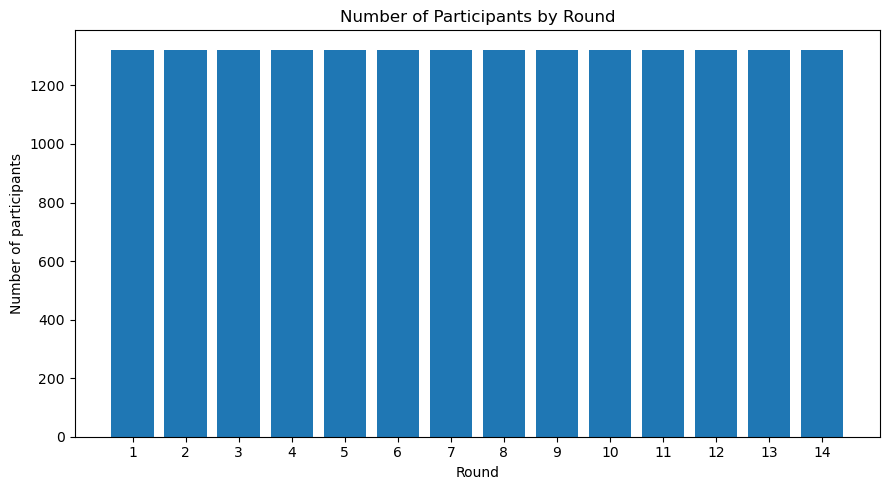

,demclas_label,count,percent
0,No dementia,15723,84.952453
1,Probable dementia,1294,6.991571
2,Possible dementia,1141,6.164902
3,Inapplicable,218,1.177869
4,Missing / not ascertained,132,0.713205


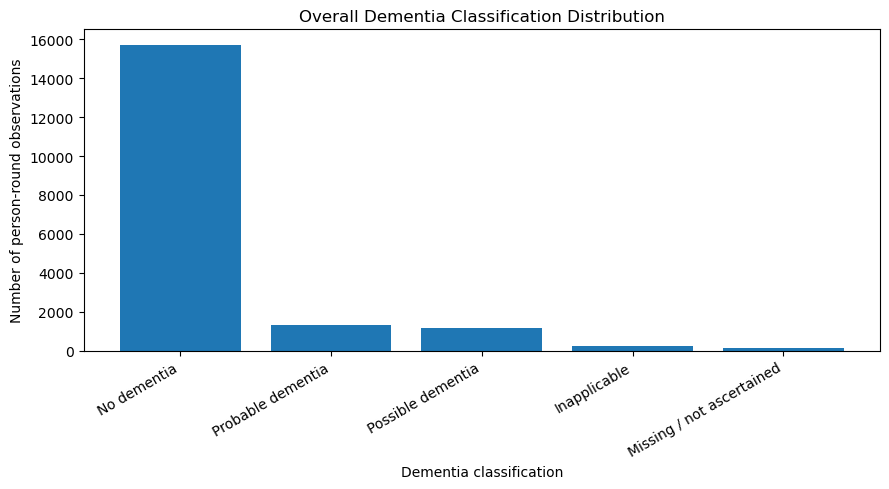

,rnd,demclas_label,count,percent_within_round
0,1,Inapplicable,6,0.453858
1,1,Missing / not ascertained,1,0.075643
2,1,No dementia,1212,91.679274
3,1,Possible dementia,85,6.429652
4,1,Probable dementia,18,1.361573
...,...,...,...,...
65,14,Inapplicable,140,10.590015
66,14,Missing / not ascertained,19,1.437216
67,14,No dementia,835,63.161876
68,14,Possible dementia,124,9.379728


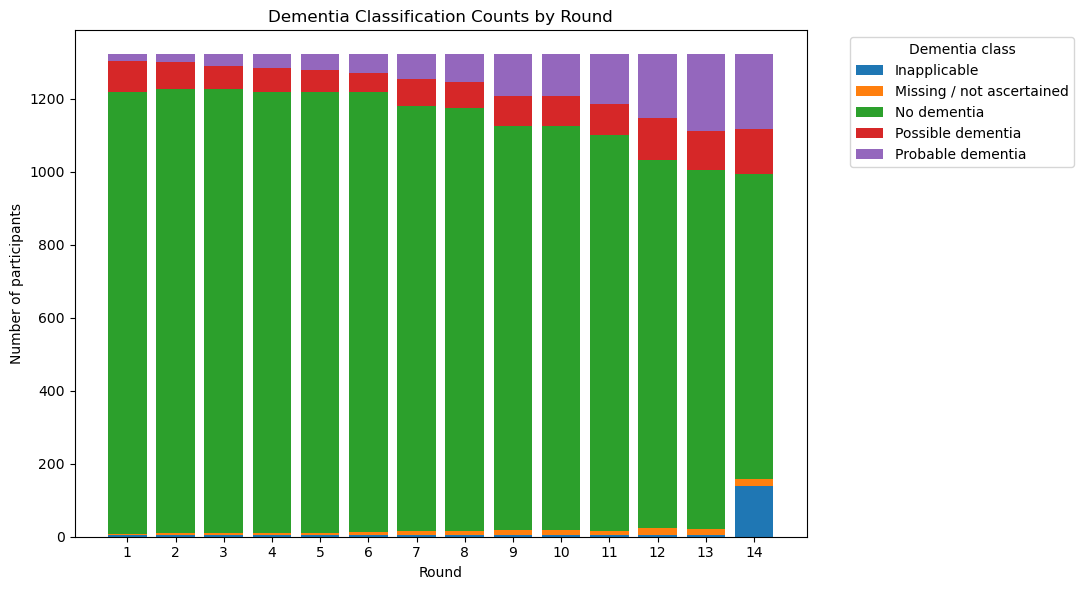

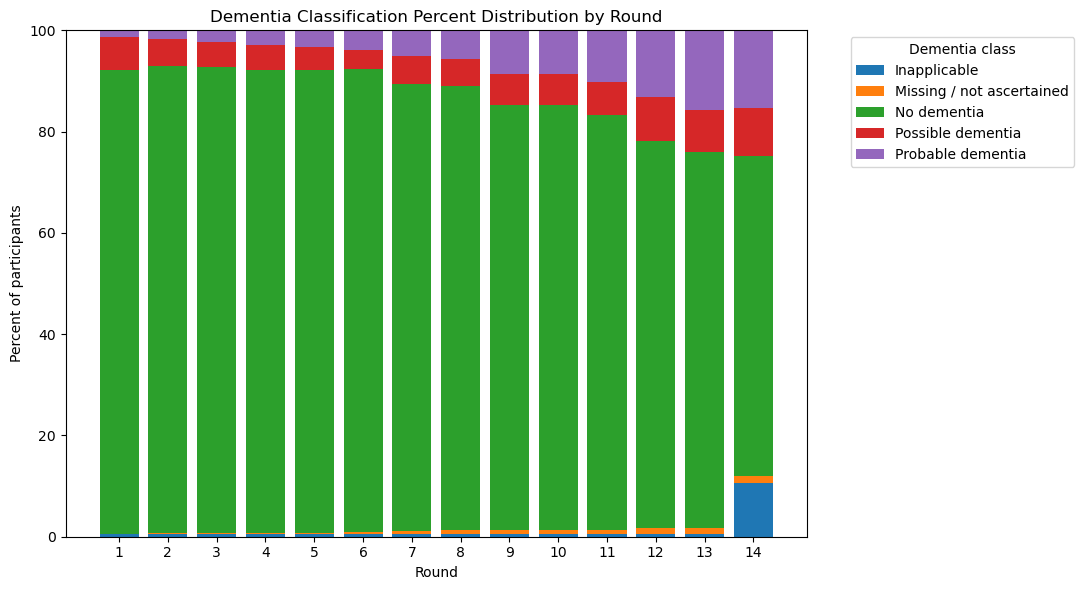

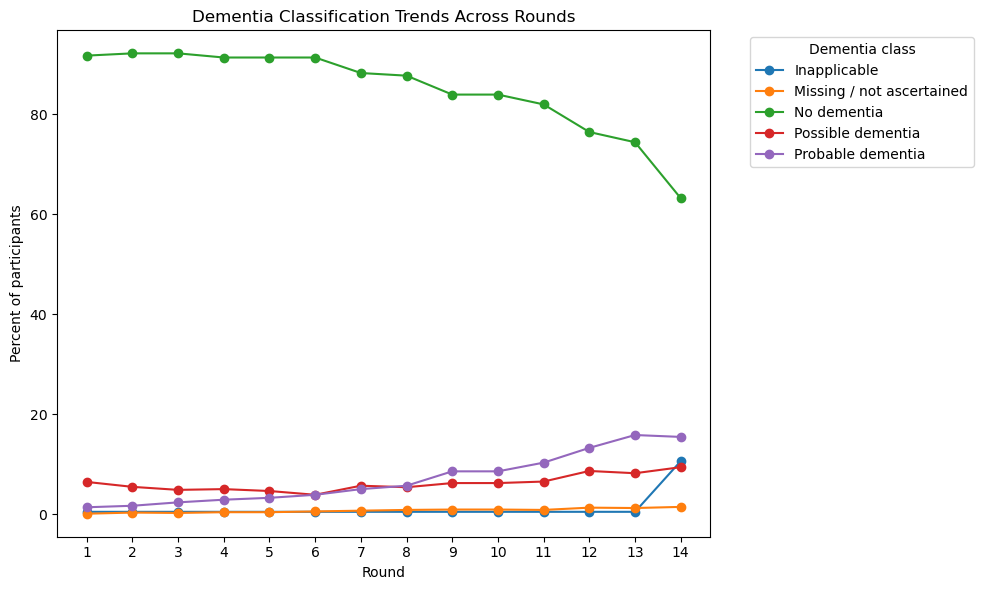

,change_status,n_participants,percent
0,Any change,669,50.605144
1,No change,653,49.394856


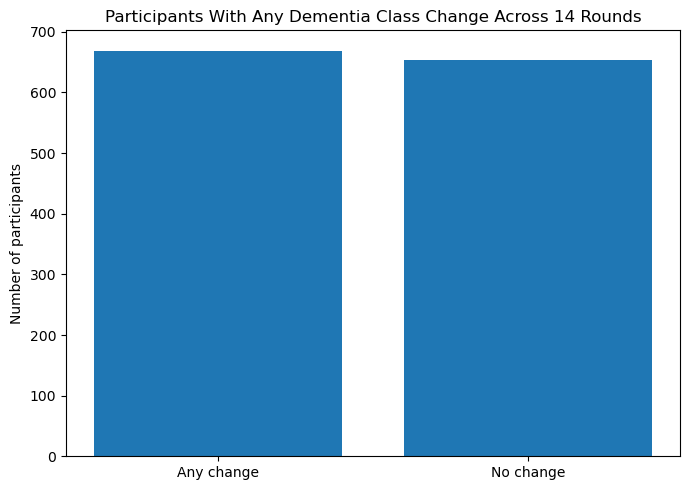

,n_unique_demclas,n_participants
0,1,653
1,2,407
2,3,207
3,4,52
4,5,3


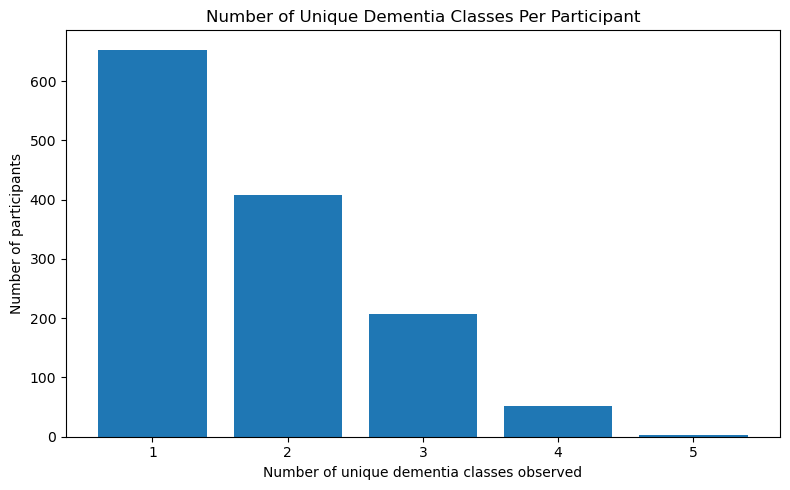

,transition,count,percent
0,No dementia → No dementia,13944,81.135808
1,Probable dementia → Probable dementia,908,5.283370
2,No dementia → Possible dementia,648,3.770511
3,Possible dementia → No dementia,505,2.938438
4,Possible dementia → Possible dementia,353,2.053997
5,No dementia → Probable dementia,220,1.280112
6,Possible dementia → Probable dementia,136,0.791342
7,Missing / not ascertained → Missing / not asce...,81,0.471314
8,Inapplicable → Inapplicable,78,0.453858
9,Probable dementia → Inapplicable,63,0.366577


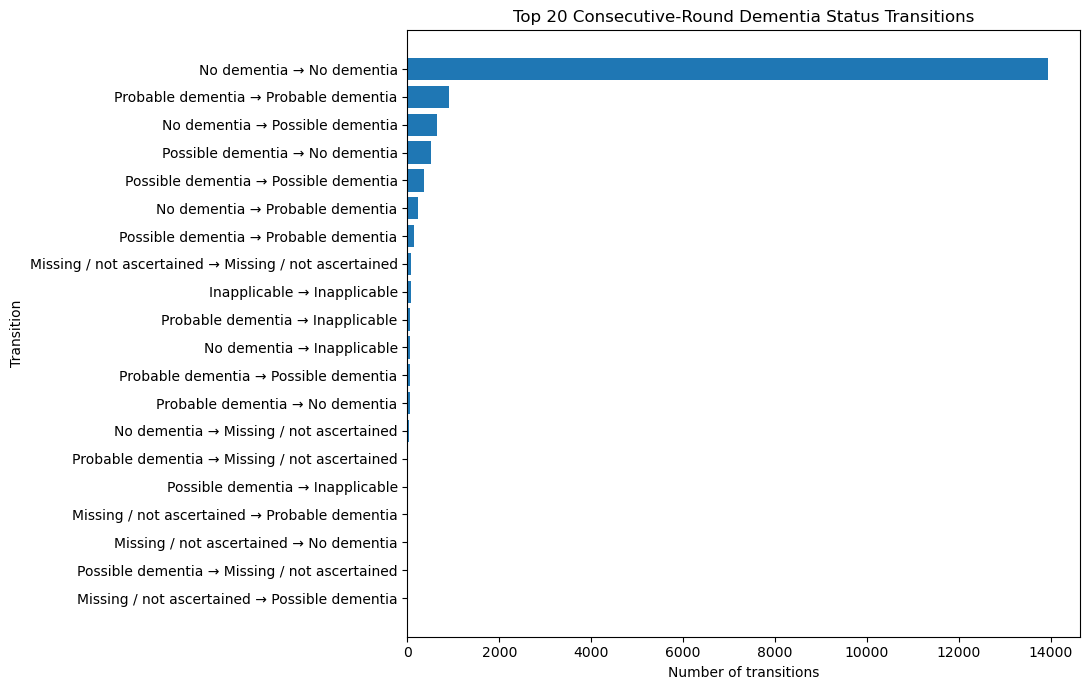

next_demclas_label,Inapplicable,Missing / not ascertained,No dementia,Possible dementia,Probable dementia
demclas_label,,,,,
Inapplicable,78,0,0,0,0
Missing / not ascertained,3,81,12,5,12
No dementia,51,25,13944,648,220
Possible dementia,17,6,505,353,136
Probable dementia,63,19,50,50,908


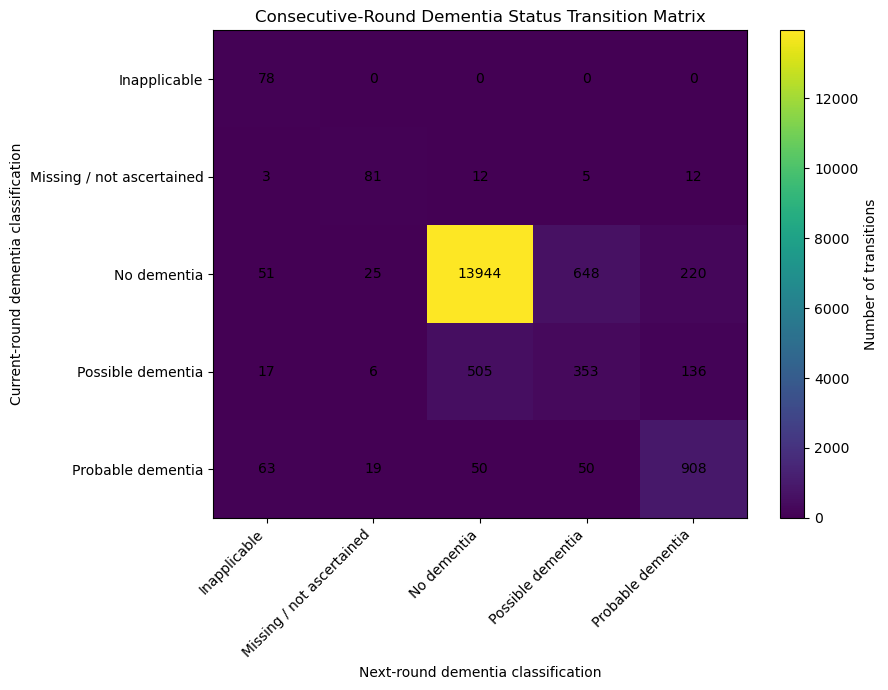

,transition_direction,count,percent
0,Stable,15205,88.473176
1,Worsened,1004,5.841964
2,Improved,605,3.520307
3,Non-classifiable / missing,372,2.164553


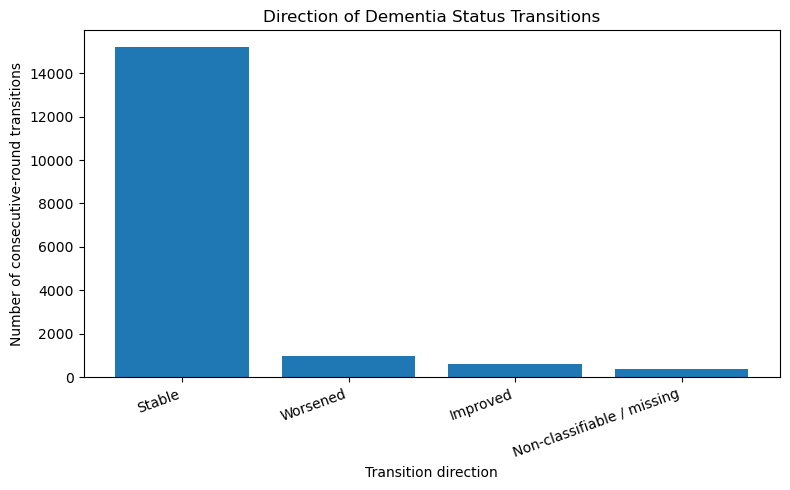

,spid,n_transitions,n_changes,n_stable,n_worsened,n_improved,n_nonclassifiable
count,1.322000e+03,1322.0,1322.000000,1322.000000,1322.000000,1322.000000,1322.000000
mean,1.000619e+07,13.0,1.378215,11.501513,0.759455,0.457640,0.281392
std,3.593715e+03,0.0,1.834750,2.144037,1.018194,0.795582,1.293237
min,1.000001e+07,13.0,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000313e+07,13.0,0.000000,11.000000,0.000000,0.000000,0.000000
50%,1.000612e+07,13.0,1.000000,12.000000,0.000000,0.000000,0.000000
75%,1.000926e+07,13.0,2.000000,13.000000,1.000000,1.000000,0.000000
max,1.001241e+07,13.0,10.000000,13.000000,5.000000,5.000000,13.000000


,n_changes,n_participants
0,0,653
1,1,179
2,2,208
3,3,100
4,4,81
5,5,49
6,6,25
7,7,15
8,8,7
9,9,3


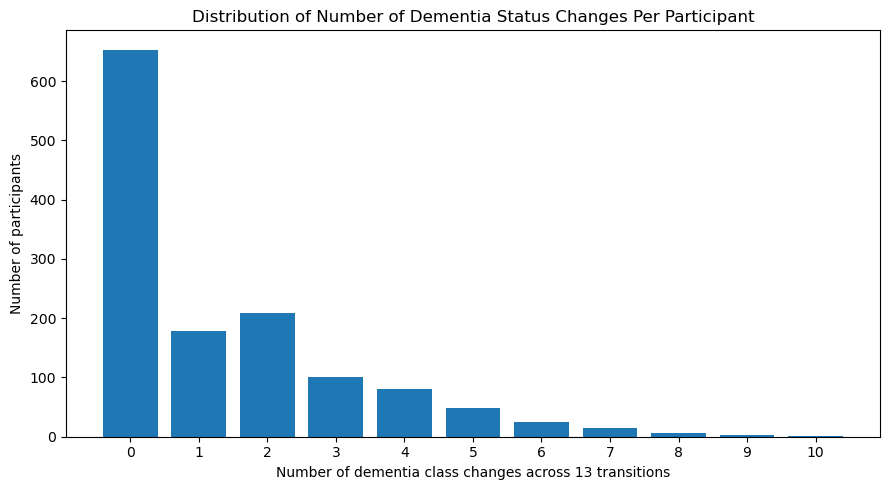

,demclas_path,n_participants,percent
0,No dementia → No dementia → No dementia → No d...,641,48.487141
1,No dementia → No dementia → No dementia → No d...,43,3.252648
2,No dementia → No dementia → No dementia → No d...,34,2.571861
3,No dementia → No dementia → No dementia → No d...,23,1.739788
4,No dementia → No dementia → No dementia → No d...,19,1.437216
5,No dementia → No dementia → No dementia → No d...,13,0.983359
6,No dementia → No dementia → No dementia → No d...,13,0.983359
7,Possible dementia → No dementia → No dementia ...,11,0.832073
8,No dementia → No dementia → No dementia → No d...,10,0.756430
9,No dementia → No dementia → No dementia → No d...,10,0.756430


/var/folders/pd/4sdc1cc90lb9pt68g676htzw0000gn/T/ipykernel_42429/2211429773.py:727: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


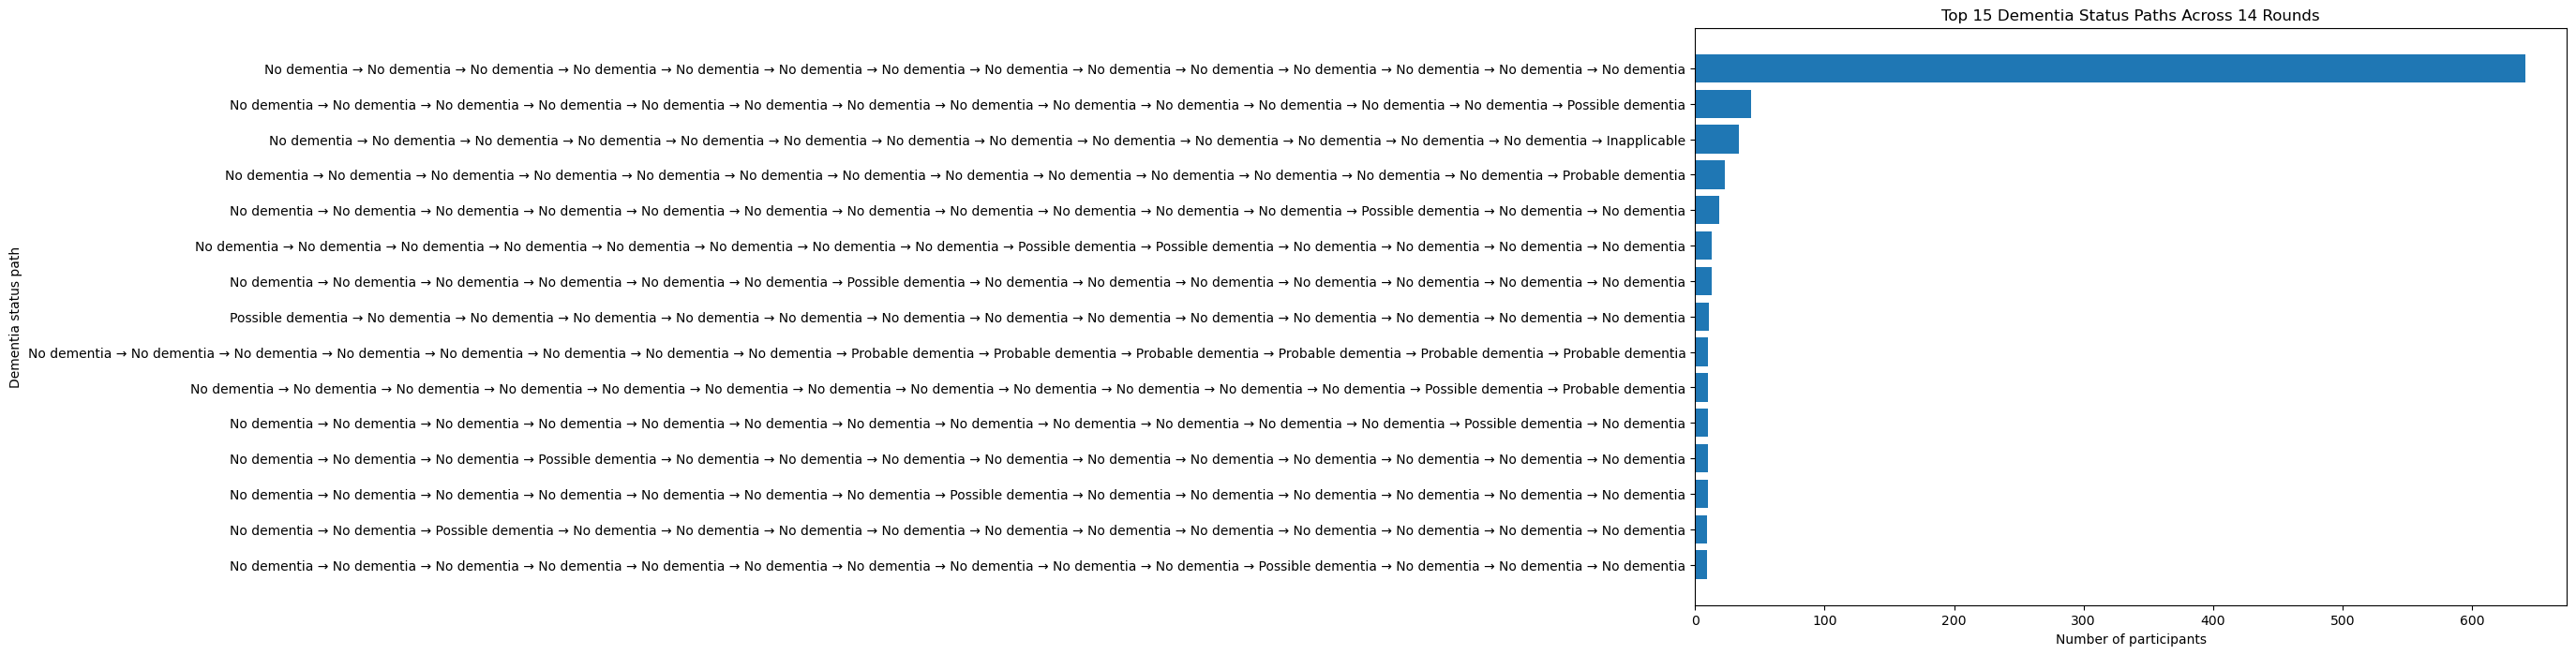

In [8]:
# descriptive statistics for the cohort of participants present in all 14 rounds

import pandas as pd

import matplotlib.pyplot as plt

from IPython.display import display

# ============================================================

# 0. Load dataset

# ============================================================

input_file = "/Users/pageguo/Desktop/nhats_data_retrieval/NHATS_Dementia_Tracking_Cohort.csv"

df = pd.read_csv(input_file)

required_cols = ["spid", "rnd", "demclas"]

missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:

    raise ValueError(f"Missing required columns: {missing_cols}")

df["rnd"] = pd.to_numeric(df["rnd"], errors="coerce")

df["demclas"] = pd.to_numeric(df["demclas"], errors="coerce")

# Dementia class labels

demclas_labels = {

    -9: "Missing / not ascertained",

    -1: "Inapplicable",

    1: "Probable dementia",

    2: "Possible dementia",

    3: "No dementia"

}

df["demclas_label"] = df["demclas"].map(demclas_labels)

df["demclas_label"] = df["demclas_label"].fillna(df["demclas"].astype(str))

df = df.sort_values(["spid", "rnd"]).reset_index(drop=True)

# ============================================================

# 1. Basic summary

# ============================================================

basic_summary = pd.DataFrame({

    "Statistic": [

        "Number of rows",

        "Number of unique participants",

        "Number of rounds",

        "Minimum round",

        "Maximum round",

        "Missing demclas values"

    ],

    "Value": [

        len(df),

        df["spid"].nunique(),

        df["rnd"].nunique(),

        df["rnd"].min(),

        df["rnd"].max(),

        df["demclas"].isna().sum()

    ]

})

display(basic_summary)

# ============================================================

# 2. Participants by round

# ============================================================

participants_by_round = (

    df.groupby("rnd")["spid"]

    .nunique()

    .reset_index(name="n_participants")

)

display(participants_by_round)

plt.figure(figsize=(9, 5))

plt.bar(participants_by_round["rnd"], participants_by_round["n_participants"])

plt.xlabel("Round")

plt.ylabel("Number of participants")

plt.title("Number of Participants by Round")

plt.xticks(participants_by_round["rnd"])

plt.tight_layout()

plt.show()

# ============================================================

# 3. Overall dementia class distribution

# ============================================================

overall_demclas = (

    df["demclas_label"]

    .value_counts()

    .reset_index()

)

overall_demclas.columns = ["demclas_label", "count"]

overall_demclas["percent"] = overall_demclas["count"] / len(df) * 100

display(overall_demclas)

plt.figure(figsize=(9, 5))

plt.bar(overall_demclas["demclas_label"], overall_demclas["count"])

plt.xlabel("Dementia classification")

plt.ylabel("Number of person-round observations")

plt.title("Overall Dementia Classification Distribution")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.show()

# ============================================================

# 4. Dementia class distribution by round

# ============================================================

demclas_by_round = (

    df.groupby(["rnd", "demclas_label"])

    .size()

    .reset_index(name="count")

)

demclas_by_round["percent_within_round"] = (

    demclas_by_round["count"]

    / demclas_by_round.groupby("rnd")["count"].transform("sum")

    * 100

)

display(demclas_by_round)

demclas_by_round_pivot_count = demclas_by_round.pivot(

    index="rnd",

    columns="demclas_label",

    values="count"

).fillna(0)

demclas_by_round_pivot_pct = demclas_by_round.pivot(

    index="rnd",

    columns="demclas_label",

    values="percent_within_round"

).fillna(0)

# Stacked count plot

plt.figure(figsize=(11, 6))

bottom = None

for col in demclas_by_round_pivot_count.columns:

    if bottom is None:

        plt.bar(demclas_by_round_pivot_count.index, demclas_by_round_pivot_count[col], label=col)

        bottom = demclas_by_round_pivot_count[col].copy()

    else:

        plt.bar(demclas_by_round_pivot_count.index, demclas_by_round_pivot_count[col], bottom=bottom, label=col)

        bottom += demclas_by_round_pivot_count[col]

plt.xlabel("Round")

plt.ylabel("Number of participants")

plt.title("Dementia Classification Counts by Round")

plt.xticks(demclas_by_round_pivot_count.index)

plt.legend(title="Dementia class", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()

plt.show()

# Stacked percentage plot

plt.figure(figsize=(11, 6))

bottom = None

for col in demclas_by_round_pivot_pct.columns:

    if bottom is None:

        plt.bar(demclas_by_round_pivot_pct.index, demclas_by_round_pivot_pct[col], label=col)

        bottom = demclas_by_round_pivot_pct[col].copy()

    else:

        plt.bar(demclas_by_round_pivot_pct.index, demclas_by_round_pivot_pct[col], bottom=bottom, label=col)

        bottom += demclas_by_round_pivot_pct[col]

plt.xlabel("Round")

plt.ylabel("Percent of participants")

plt.title("Dementia Classification Percent Distribution by Round")

plt.xticks(demclas_by_round_pivot_pct.index)

plt.ylim(0, 100)

plt.legend(title="Dementia class", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()

plt.show()

# Line plot of class percentages over rounds

plt.figure(figsize=(10, 6))

for col in demclas_by_round_pivot_pct.columns:

    plt.plot(demclas_by_round_pivot_pct.index, demclas_by_round_pivot_pct[col], marker="o", label=col)

plt.xlabel("Round")

plt.ylabel("Percent of participants")

plt.title("Dementia Classification Trends Across Rounds")

plt.xticks(demclas_by_round_pivot_pct.index)

plt.legend(title="Dementia class", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()

plt.show()

# ============================================================

# 5. Within-person dementia status change

# ============================================================

demclas_change_summary = (

    df.groupby("spid")["demclas"]

    .nunique()

    .reset_index(name="n_unique_demclas")

)

demclas_change_summary["change_status"] = demclas_change_summary["n_unique_demclas"].apply(

    lambda x: "No change" if x == 1 else "Any change"

)

change_counts = (

    demclas_change_summary["change_status"]

    .value_counts()

    .reset_index()

)

change_counts.columns = ["change_status", "n_participants"]

change_counts["percent"] = change_counts["n_participants"] / change_counts["n_participants"].sum() * 100

display(change_counts)

plt.figure(figsize=(7, 5))

plt.bar(change_counts["change_status"], change_counts["n_participants"])

plt.xlabel("")

plt.ylabel("Number of participants")

plt.title("Participants With Any Dementia Class Change Across 14 Rounds")

plt.tight_layout()

plt.show()

# Number of unique classes per participant

unique_class_distribution = (

    demclas_change_summary["n_unique_demclas"]

    .value_counts()

    .sort_index()

    .reset_index()

)

unique_class_distribution.columns = ["n_unique_demclas", "n_participants"]

display(unique_class_distribution)

plt.figure(figsize=(8, 5))

plt.bar(unique_class_distribution["n_unique_demclas"], unique_class_distribution["n_participants"])

plt.xlabel("Number of unique dementia classes observed")

plt.ylabel("Number of participants")

plt.title("Number of Unique Dementia Classes Per Participant")

plt.xticks(unique_class_distribution["n_unique_demclas"])

plt.tight_layout()

plt.show()

# ============================================================

# 6. Consecutive-round transitions

# ============================================================

df_transition = df[["spid", "rnd", "demclas", "demclas_label"]].copy()

df_transition = df_transition.sort_values(["spid", "rnd"])

df_transition["next_rnd"] = df_transition.groupby("spid")["rnd"].shift(-1)

df_transition["next_demclas"] = df_transition.groupby("spid")["demclas"].shift(-1)

df_transition["next_demclas_label"] = df_transition.groupby("spid")["demclas_label"].shift(-1)

df_transition = df_transition[

    df_transition["next_rnd"] == df_transition["rnd"] + 1

].copy()

df_transition["transition"] = (

    df_transition["demclas_label"].astype(str)

    + " → "

    + df_transition["next_demclas_label"].astype(str)

)

transition_counts = (

    df_transition["transition"]

    .value_counts()

    .reset_index()

)

transition_counts.columns = ["transition", "count"]

transition_counts["percent"] = transition_counts["count"] / transition_counts["count"].sum() * 100

display(transition_counts.head(20))

top_transitions = transition_counts.head(20)

plt.figure(figsize=(11, 7))

plt.barh(top_transitions["transition"], top_transitions["count"])

plt.xlabel("Number of transitions")

plt.ylabel("Transition")

plt.title("Top 20 Consecutive-Round Dementia Status Transitions")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

# Transition matrix

transition_matrix = pd.crosstab(

    df_transition["demclas_label"],

    df_transition["next_demclas_label"]

)

display(transition_matrix)

plt.figure(figsize=(9, 7))

plt.imshow(transition_matrix.values, aspect="auto")

plt.colorbar(label="Number of transitions")

plt.xticks(

    range(len(transition_matrix.columns)),

    transition_matrix.columns,

    rotation=45,

    ha="right"

)

plt.yticks(

    range(len(transition_matrix.index)),

    transition_matrix.index

)

plt.xlabel("Next-round dementia classification")

plt.ylabel("Current-round dementia classification")

plt.title("Consecutive-Round Dementia Status Transition Matrix")

for i in range(transition_matrix.shape[0]):

    for j in range(transition_matrix.shape[1]):

        plt.text(

            j,

            i,

            int(transition_matrix.iloc[i, j]),

            ha="center",

            va="center"

        )

plt.tight_layout()

plt.show()

# ============================================================

# 7. Transition direction: stable, worsened, improved

# ============================================================

severity_map = {

    1: 1,  # Probable dementia

    2: 2,  # Possible dementia

    3: 3   # No dementia

}

df_transition["severity_now"] = df_transition["demclas"].map(severity_map)

df_transition["severity_next"] = df_transition["next_demclas"].map(severity_map)

def classify_transition(row):

    if pd.isna(row["severity_now"]) or pd.isna(row["severity_next"]):

        return "Non-classifiable / missing"

    elif row["severity_next"] == row["severity_now"]:

        return "Stable"

    elif row["severity_next"] < row["severity_now"]:

        return "Worsened"

    elif row["severity_next"] > row["severity_now"]:

        return "Improved"

    else:

        return "Other"

df_transition["transition_direction"] = df_transition.apply(classify_transition, axis=1)

transition_direction_counts = (

    df_transition["transition_direction"]

    .value_counts()

    .reset_index()

)

transition_direction_counts.columns = ["transition_direction", "count"]

transition_direction_counts["percent"] = (

    transition_direction_counts["count"]

    / transition_direction_counts["count"].sum()

    * 100

)

display(transition_direction_counts)

plt.figure(figsize=(8, 5))

plt.bar(transition_direction_counts["transition_direction"], transition_direction_counts["count"])

plt.xlabel("Transition direction")

plt.ylabel("Number of consecutive-round transitions")

plt.title("Direction of Dementia Status Transitions")

plt.xticks(rotation=20, ha="right")

plt.tight_layout()

plt.show()

# ============================================================

# 8. Participant-level number of changes

# ============================================================

participant_transition_summary = (

    df_transition

    .assign(changed=lambda x: x["demclas"] != x["next_demclas"])

    .groupby("spid")

    .agg(

        n_transitions=("transition", "count"),

        n_changes=("changed", "sum"),

        n_stable=("transition_direction", lambda x: (x == "Stable").sum()),

        n_worsened=("transition_direction", lambda x: (x == "Worsened").sum()),

        n_improved=("transition_direction", lambda x: (x == "Improved").sum()),

        n_nonclassifiable=("transition_direction", lambda x: (x == "Non-classifiable / missing").sum())

    )

    .reset_index()

)

display(participant_transition_summary.describe())

n_changes_distribution = (

    participant_transition_summary["n_changes"]

    .value_counts()

    .sort_index()

    .reset_index()

)

n_changes_distribution.columns = ["n_changes", "n_participants"]

display(n_changes_distribution)

plt.figure(figsize=(9, 5))

plt.bar(n_changes_distribution["n_changes"], n_changes_distribution["n_participants"])

plt.xlabel("Number of dementia class changes across 13 transitions")

plt.ylabel("Number of participants")

plt.title("Distribution of Number of Dementia Status Changes Per Participant")

plt.xticks(n_changes_distribution["n_changes"])

plt.tight_layout()

plt.show()

# ============================================================

# 9. Full dementia status paths

# ============================================================

path_summary = (

    df.sort_values(["spid", "rnd"])

    .groupby("spid")["demclas_label"]

    .apply(lambda x: " → ".join(x.astype(str)))

    .reset_index(name="demclas_path")

)

path_counts = (

    path_summary["demclas_path"]

    .value_counts()

    .reset_index()

)

path_counts.columns = ["demclas_path", "n_participants"]

path_counts["percent"] = path_counts["n_participants"] / path_counts["n_participants"].sum() * 100

display(path_counts.head(15))

top_paths = path_counts.head(15)

plt.figure(figsize=(12, 8))

plt.barh(top_paths["demclas_path"], top_paths["n_participants"])

plt.xlabel("Number of participants")

plt.ylabel("Dementia status path")

plt.title("Top 15 Dementia Status Paths Across 14 Rounds")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()